# Numari.com

BASE
- Poder crear tablero en base a un txt
- Mover con las teclas
- Validar movimientos

Extras:
- Crear un contador
- Boton de reestablecer

## CONSTANTES:

- CANTIDAD MAXIMA DE CELDAS LLENAS: 6
- CANTIDAD MINIMA DE CELDAS LLENAS: 4
- VALOR MAXIMO DE UNA CELDA: 4
- VALOR MINIMO DE UNA CELDA: 0

## Sintaxis de tableros

El tablero es una cuadrícula de tamaño n × n.
Cada celda puede contener:

Número (0, 1, 2, 3, 4) → Indica cuántos caminos deben pasar por esa celda.

C (Celda vacía) → Espacio sin restricción.

F (Final) → Celda de llegada obligatoria.

La solución del tablero se representa con direcciones en cada celda:

U = Up (arriba)

D = Down (abajo)

L = Left (izquierda)

R = Right (derecha)

F = Final

Ejemplo:

### Tablero con celdas vacias y celdas llenas
C 4 C C

C C C 2

3 C C C

C C C 3

C = Letra vacia

### Solucion del tablero:
D L F L

R D R U

D L U L

R R R U

- F = Final 
- D = Down (abajo)
- U = Up (arriba)
- R = Right (derecha)
- L = Left (izquierda)

### Algoritmo de validación

- Localizar la celda final (F).

- Guardar sus coordenadas (x, y).

- Marcarla como explorada.

- Explorar en reversa (desde F hacia atrás):

- Mientras existan celdas no exploradas:

- Revisar celdas adyacentes (arriba, abajo, izquierda, derecha).

- Comprobar si la dirección de esa celda apunta hacia la actual.

- Ejemplo: si estoy en (x, y) y la celda (x-1, y) tiene R, entonces está conectada.

- Marcar esa celda como explorada y continuar desde allí.




## Movimientos y configuraciones no permitidos

Un tablero es inválido si contiene alguna de las siguientes situaciones:

Movimientos contradictorios en una misma celda

Secuencia L seguido de R, o R seguido de L.

Secuencia U seguido de D, o D seguido de U.

Justificación: el camino se cancela a sí mismo y nunca llegaría al final.

Movimientos que salen de los límites del tablero

U en la primera fila (fila 0).

D en la última fila.

L en la primera columna (columna 0).

R en la última columna.

Justificación: el camino se fuga fuera del tablero, lo cual es inválido.

Restricciones numéricas inválidas

Dos números mayores que 0 adyacentes entre sí (horizontal o vertical).

Justificación: se generan restricciones imposibles de cumplir.

Dos o más celdas con valor 0.

Justificación: solo puede existir una celda “cero” como restricción especial.

In [1]:
import random
import time

In [2]:
class Board:
    
    
    
    # Movement
    VALIDATE_MOVEMENT = ['U', 'D', 'L', 'R']
    FINAL_SIGN = 'F'
    # U: Up
    # D: Down
    # L: Left
    # R: Right
    
    def __init__(self, board:list=None, n:int=4):
        """
        board: List of lists of the board, None for generate a random board
        n: lenght of board n*n"""
        self.length = n
        if not board:
            pass
        
        pass
    
    def _generate_board(self):
        board = [['UDLRF' for _ in range(self.length)] for _ in range(self.length)]
        
        
    def validate(self):
        pass
    
    def show(self):
        pass
    
    
    
    

# CSP

In [3]:
class Backtrack:
    
    def __valid_edges(board):

        board = [[cell for cell in row] for row in board]
        length = len(board)
        
        # En la fila superior no puedes ir hacia arriba.
        # En la fila inferior no puedes ir hacia abajo.
        # En la primera columna no puedes ir a la izquierda.
        # En la última columna no puedes ir a la derecha.

        for position in [0, length-1]:
            
            letter_1, letter_2 = ('U', 'L') if position == 0 else ('D', 'R')
            for i in range(length):
                board[position][i] = board[position][i].replace(letter_1, '')
                board[i][position] = board[i][position].replace(letter_2, '')
        
        return board
    
    def __unique_final(board):
        "Ensure that only has a final"
        
        find_final = False
        
        for row in board:
            for cell in row:
                
                if not cell == 'F': continue
                
                # If the actual cell is F and F is finded it means there are two F
                if find_final: return False
                
                find_final = True
                
        return True
    
    def __clean_movements(board, position):
    
        board = [[cell for cell in row] for row in board]
        length = len(board)
        
        x, y = position
        
        invalid_move = {'R':(x-1, y), 'L':(x+1, y), 'D': (x, y-1), 'U':(x, y+1)}
        
        for letter, new_position in invalid_move.items():
            
            if any(value >= length for value in new_position): continue
            new_x, new_y = new_position
            
            if len(board[new_y][new_x]) == 1:
                continue
            board[new_y][new_x] = board[new_y][new_x].replace(letter, '')
        
        return board
    
    def __move_to(position, move):
        x,y = position
        movements = {'R':(x+1, y), 'L':(x-1, y), 'D': (x, y+1), 'U':(x, y-1)}
        return movements[move]
    
    
    def solve(board, position:tuple=None, cells_explored:int=0):
    
        board = [[cell for cell in row] for row in board]
        length = len(board)
        
        # If no cell explored, clean edges
        if cells_explored == 0:
            board = Backtrack.__valid_edges(board=board)
        
        # If there are more than a Final, Can't solve the board
        if not Backtrack.__unique_final(board): 
            return None
        
        # Validate that board is not full
        if cells_explored == length**2 -1:
            return board, position
        
        if not position:
            x = random.randint(0, length-1)
            y = random.randint(0, length-1)
        else:
            x, y = position
    
        move = board[y][x].replace('F', '')
        
        all_move = [letter for letter in move]
        random.shuffle(all_move)
        
        move = board[y][x]
        
        for letter in all_move:
            
            new_board = Backtrack.__clean_movements(board=board, position=(x, y))
            new_x, new_y = Backtrack.__move_to(position=(x, y), move=letter)
            
            new_board[y][x] = letter
            
            value_return = Backtrack.solve(board=new_board, position=(new_x, new_y), cells_explored=cells_explored+1)
            
            if value_return: 
                new_board, _ = value_return
                return new_board, (x, y)

In [4]:
board = [['UDLRF' for _ in range(4)] for _ in range(4)]

In [5]:
Backtrack.solve(board=board)

([['D', 'L', 'L', 'F'],
  ['D', 'R', 'D', 'U'],
  ['D', 'U', 'D', 'U'],
  ['R', 'U', 'R', 'U']],
 (2, 0))

In [6]:
def move_to(position, move):
    x,y = position
    movements = {'R':(x+1, y), 'L':(x-1, y), 'D': (x, y+1), 'U':(x, y-1)}
    return movements[move]

def generate_values(board, begin_position):
    
    board = [[cell for cell in row] for row in board]
    cells = len(board)**2
    x, y = begin_position
    
    # Max and Min quantity of cell with numbers
    MAX_NUM_CELLS = 6
    MIN_NUM_CELLS = 4
    MAX_VALUE_IN_CELL = 4
    MIN_VALUE_IN_CELL = 0
    
    numbers = [0 for i  in range(random.randint(MIN_NUM_CELLS, MAX_NUM_CELLS))]
    avaible_cells = cells - len(numbers)
    valid_values = [0, 1, 2, 3, 4]
    while sum(numbers) != avaible_cells or any([j not in valid_values for j in numbers]):
        for i in range(len(numbers)-1):
            numbers[i] = random.randint(MIN_VALUE_IN_CELL, MAX_VALUE_IN_CELL)
        numbers[len(numbers)-1] = avaible_cells - sum(numbers)   
    
    current_value = ''
    number_idx = 0 
    
    for number in numbers:
        if board[y][x] == 'F':
                board[y][x] = ' '
                return board
        new_x, new_y = move_to((x, y), board[y][x])
        board[y][x] = number
        x, y = new_x, new_y
        for _ in range(number):
            
            if board[y][x] == 'F':
                board[y][x] = ' '
                return board
            
            new_x, new_y = move_to((x, y), board[y][x])
            board[y][x] = ' '
            x, y = new_x, new_y
    


In [7]:
board = [['D', 'L', 'R', 'D'],
  ['D', 'R', 'U', 'F'],
  ['D', 'U', 'L', 'L'],
  ['R', 'R', 'R', 'U']]

In [8]:
a = generate_values(board, (1, 0))

In [9]:
for row in a:
    print(row)

[' ', 2, 2, ' ']
[' ', ' ', ' ', ' ']
[4, ' ', ' ', 4]
[' ', ' ', ' ', ' ']


In [ ]:
class Control:
    
    @staticmethod
    def play() -> tuple[int, int]:
        while True:
            print('Presiona una tecla (WSAD)')
            key = input().upper()
            
            
            match key:
                
                case 'W': return (0, -1)
                case 'S': return (0, 1)
                case 'A': return (-1, 0)
                case 'D': return (1, 0)
                case 'C': return key
                case 'ESC': return key
            
    @staticmethod
    def right_left() -> int:
        while True:
            print('Presiona una tecla (AD)')
            key = input().upper()
            
            
            match key:
            
                case 'A': return -1
                case 'D': return 1
                case 'ENTER': return key
                case 'ESC': return key
    
    @staticmethod
    def up_down() -> tuple[int, int]:
        while True:
            print('Presiona una tecla (WS)')
            key = input().upper()
            
            
            match key:
                
                case 'W': return -1
                case 'S': return 1
                case 'ENTER': return key
    
    

In [ ]:
class Menu:
    
    def __init__(self, sections:list, menu_name='Menu') -> None:
        self.menu_sections = sections
        self.menu_name = menu_name
    
    def select(self) -> int:
        
        print('' + '='*5 + f' {self.menu_name} ' + '='*5)
        position = 0
        
        while True:
            for i in range(len(self.menu_sections)):


                if i == position:
                    print(f'> \033[31m{self.menu_sections[i]}\033[0m <')
                else:   
                    print(self.menu_sections[i])
                
            selected = Control.up_down()
            if selected == 'ENTER':
                return position
            else:
                
                position += selected
                if position < 0: position = 0
                if position >= len(self.menu_sections): position = len(self.menu_sections)-1

In [28]:
b = Menu(['Jugar', 'Opciones', 'Salir'], menu_name='Numari')
b.select()

===== Numari =====
> Jugar <
Opciones
Salir
Presiona una tecla (WSAD)
Jugar
> Opciones <
Salir
Presiona una tecla (WSAD)
Jugar
Opciones
> Salir <
Presiona una tecla (WSAD)
Jugar
Opciones
> Salir <
Presiona una tecla (WSAD)
Jugar
Opciones
> Salir <
Presiona una tecla (WSAD)
Jugar
> Opciones <
Salir
Presiona una tecla (WSAD)


1

===== Numari =====
> Jugar <
Opciones
Salir


In [ ]:
class NumariBoard:
    
    def __init__(self, board:list=None, n:int=4):
        """
        board: List of lists of the board, None for generate a random board
        n: lenght of board n*n"""
        
        if not board:
            self.length = n
            board = self.new_board(n)
        
        self.board = board
        self.length = len(board)
        self.positions = self._numbers_position()
    
    
    def new_board(self, length):
        board = [['UDLRF' for _ in range(length)] for _ in range(length)]
        board, begin = Backtrack.solve(board)
        board = self.__generate_values(board, begin)
        return board
    
    @staticmethod
    def _move_to(position, move):
        x,y = position
        movements = {'R':(x+1, y), 'L':(x-1, y), 'D': (x, y+1), 'U':(x, y-1)}
        return movements[move]    
    
    def __generate_values(self, board, begin_position):
        board = [[cell for cell in row] for row in board]
        cells = self.length**2
        x, y = begin_position
        
        # Max and Min quantity of cell with numbers
        MAX_NUM_CELLS = 6
        MIN_NUM_CELLS = 4
        MAX_VALUE_IN_CELL = 4
        MIN_VALUE_IN_CELL = 0
        
        numbers = [0 for i  in range(random.randint(MIN_NUM_CELLS, MAX_NUM_CELLS))]
        avaible_cells = cells - len(numbers)
        valid_values = [0, 1, 2, 3, 4]
        while sum(numbers) != avaible_cells or any([j not in valid_values for j in numbers]):
            for i in range(len(numbers)-1):
                numbers[i] = random.randint(MIN_VALUE_IN_CELL, MAX_VALUE_IN_CELL)
            numbers[len(numbers)-1] = avaible_cells - sum(numbers)   
        
        for number in numbers:
            if board[y][x] == 'F':
                    board[y][x] = ' '
                    return board
            new_x, new_y = NumariBoard._move_to((x, y), board[y][x])
            board[y][x] = number
            x, y = new_x, new_y
            for _ in range(number):
                
                if board[y][x] == 'F':
                    board[y][x] = ' '
                    return board
                
                new_x, new_y = NumariBoard._move_to((x, y), board[y][x])
                board[y][x] = ' '
                x, y = new_x, new_y
                
    def _numbers_position(self):
        positions = []
        
        for y in range(self.length):
            for x in range(self.length):
                
                if isinstance(self.board[y][x], int):
                    positions.append((x, y))
        
        return positions
    
    
    def show_game(self, board, collected, problem=None):
        
        numbers_positions, movements = collected      
        orange_cells = []
        
       
        for i in range(len(movements)):
            orange_cells.append(movements[-(i+1)])
            if movements[-(i+1)] == numbers_positions[-1]:
                x, y = numbers_positions[-1]
                if i == board[y][x]:
                    orange_cells = []
                break
                    
        # 34: Azul
        # 32: Verde
        # 38;5;208: Naranja
        # 31: Rojo    
        
        for y in range(self.length):
            for x in range(self.length):
                
                # Naranja para celdas incompletas 
                if (x, y) in orange_cells:
                    print(f'| \033[38;5;208m{board[y][x]}\033[0m ', end='')  
                
                # Verde para celdas ya completadas      
                elif (x, y) in movements: 
                    print(f'| \033[32m{board[y][x]}\033[0m ', end='') 
                    
                # Rojo para celda a la que no se puede mover
                elif (x, y) == problem:
                    # # SI la celda esta vacia pinta el cuadro rojo vacio
                    # if board[y][x] == ' ':
                    #     print("\033[41m   \033[0m")
                    # # Si no esta vacia pinta el cuadro rojo con el numero
                    # else:
                    #     print(F"| \033[41m{print("\033[41m   \033[0m")}\033[0m |")  
                    
                    print(f'|\033[41m {board[y][x]} \033[0m', end='')
                    
                elif isinstance(board[y][x], int):
                    print(f'| \033[34m{board[y][x]}\033[0m ', end='')
                else:
                    print(f'| {board[y][x]} ', end='')
            print('|')
            print(f"{'-'* (self.length* 4)}-")
                
                
                
                
    def show_board(self, actual_position=None, board=None):
        if not board:
            board = self.board
        print(f"{'-'* (self.length* 4)}-")
        for y in range(self.length):
            for x in range(self.length):
                
                
                if actual_position and actual_position==(x,y):
                    
                    # \033[31mTexto rojo\033[0m
                    print(f'| \033[34m{board[y][x]}\033[0m ', end='')
                else:
                    print(f'| {board[y][x]} ', end='')

            print('|')
            print(f"{'-'* (self.length* 4)}-")
        
    def __select_begin_cell(self):
        
        begins_position = self._numbers_position()
        positions_quantity = len(begins_position)
        
        position = 0
        while True:
            self.show_board(begins_position[position])
            human_play = Control.right_left()
            if isinstance(human_play, str):
                if human_play == 'ENTER':
                    return (begins_position[position])
            
                else: 
                    return None
            if position == 0 and human_play == -1:
                position = positions_quantity-1
            elif position == positions_quantity-1 and human_play == 1:
                position = 0
            else:
                position += human_play
            
        
    def play(self):
        
        while True:
            board =  [[cell for cell in row] for row in self.board]
            begin_position = self.__select_begin_cell()
            
            if begin_position:
                x, y = begin_position
            else:
                break
            
            collected_cells = [[False for _ in range(self.length)] for _ in range(self.length)]
            x_number, y_number = x, y
            movements = []
            numbers_positions = []
            i_position = 0
            collected_cells[y][x] = True
            
            
            print(self.length**2)
            
            while len(numbers_positions) <= self.length**2:
                
                while i_position <= board[y_number][x_number]:
                    
                    temporal_movements = movements.copy()
                    temporal_numbers_positions = numbers_positions.copy()
                    temporal_movements.append((x, y))
                    temporal_numbers_positions.append((x_number, y_number))
                    
                    self.show_game(board, (temporal_numbers_positions, temporal_movements))            
                    # self.show_board((x, y), board)
                       
                    move = Control.play()
                        
                    if isinstance(move, str):
                        return
                        
                    new_x, new_y = x + move[0], y + move[1]
                        
                    if not (0 <= new_x < self.length) or (not 0 <= new_y < self.length):
                        continue
                    if movements and movements[-1] == (new_x, new_y):
                        i_position -= 1
                        movements.pop()
                        collected_cells[y][x] = False
                        if i_position < 0 and numbers_positions:
                            x_number, y_number = numbers_positions.pop()
                            i_position = board[y_number][x_number]
                        else:
                            board[y][x] = " "
                        
                        x, y = new_x, new_y
                        continue
                    
                    if collected_cells[new_y][new_x]:                        
                        continue
                        
                    if board[new_y][new_x] != " " and i_position < board[y_number][x_number]:
                        self.show_game(board=board, collected=(temporal_numbers_positions, temporal_movements), problem=(new_x, new_y))
                        time.sleep(0.5) 
                        continue
                    
                    if i_position == board[y_number][x_number] and board[new_y][new_x] == " ":
                        self.show_game(board=board, collected=(temporal_numbers_positions, temporal_movements), problem=(new_x, new_y))
                        time.sleep(0.5) 
                        continue
                    
                    movements.append((x, y))
                    board[new_y][new_x] = 'X' if board[new_y][new_x] == ' ' else board[new_y][new_x]
                    x, y = new_x, new_y
                    collected_cells[y][x] = True
                    i_position += 1

                    if any(all(all(row) for row in collected_cells) for row in collected_cells):
                        print("Ganaste")
                        self.show_game(board, (temporal_numbers_positions, temporal_movements))
                        return

                    
                numbers_positions.append((x_number, y_number))
                
                x_number, y_number = x, y
                i_position = 0
            
                
            break
                    

In [12]:
numari = [
        [3, ' ', ' ', 2],
        [' ', 1, ' ', 0],
        [' ', ' ', ' ', 2],
        [' ', 2, ' ', ' ']
]

In [14]:
a = NumariBoard(numari)
# a.play()

In [ ]:
a.show_board((1, 1))

-----------------
| 3 |   |   | 2 |
-----------------
|   | 1 |   | 0 |
-----------------
|   |   |   | 2 |
-----------------
|   | 2 |   |   |
-----------------


In [ ]:
# Control.play()

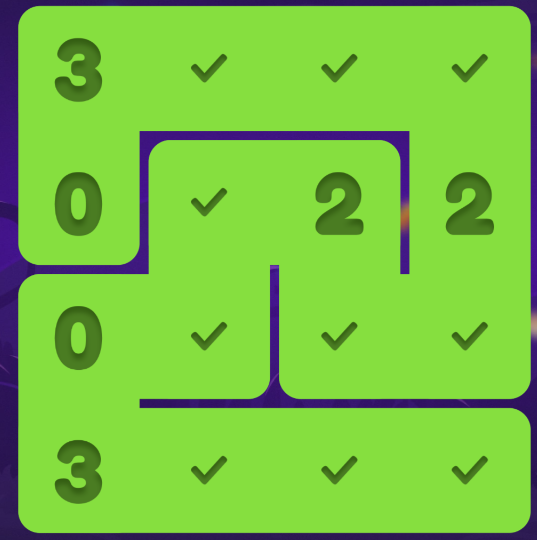

In [ ]:
def valid_edges(board):
    
    board = [[cell for cell in row] for row in board]
    length = len(board)
    
    # En la fila superior no puedes ir hacia arriba.
    # En la fila inferior no puedes ir hacia abajo.
    # En la primera columna no puedes ir a la izquierda.
    # En la última columna no puedes ir a la derecha.

    for position in [0, length-1]:
        
        letter_1, letter_2 = ('U', 'L') if position == 0 else ('D', 'R')
        for i in range(length):
            board[position][i] = board[position][i].replace(letter_1, '')
            board[i][position] = board[i][position].replace(letter_2, '')
    
    return board

In [ ]:
board = [['UDLRF' for _ in range(4)] for _ in range(4)]

In [ ]:
board

[['UDLRF', 'UDLRF', 'UDLRF', 'UDLRF'],
 ['UDLRF', 'UDLRF', 'UDLRF', 'UDLRF'],
 ['UDLRF', 'UDLRF', 'UDLRF', 'UDLRF'],
 ['UDLRF', 'UDLRF', 'UDLRF', 'UDLRF']]

In [ ]:
valid_edges(board)

[['DRF', 'DLRF', 'DLRF', 'DLF'],
 ['UDRF', 'UDLRF', 'UDLRF', 'UDLF'],
 ['UDRF', 'UDLRF', 'UDLRF', 'UDLF'],
 ['URF', 'ULRF', 'ULRF', 'ULF']]

In [ ]:
def unique_final(board):
    "Ensure that only has a final"
    
    find_final = False
    
    for row in board:
        for cell in row:
            
            if not cell == 'F': continue
            
            # If the actual cell is F and F is finded it means there are two F
            if find_final: return False
            
            find_final = True
            
    return True
    

In [ ]:
def clean_movements(board, position):
    
    board = [[cell for cell in row] for row in board]
    length = len(board)
    
    x, y = position
    
    invalid_move = {'R':(x-1, y), 'L':(x+1, y), 'D': (x, y-1), 'U':(x, y+1)}
    
    for letter, new_position in invalid_move.items():
        
        if any(value >= length for value in new_position): continue
        new_x, new_y = new_position
        
        if len(board[new_y][new_x]) == 1:
            continue
        board[new_y][new_x] = board[new_y][new_x].replace(letter, '')
    
    return board

In [ ]:
def move_to(position, move):
    x,y = position
    movements = {'R':(x+1, y), 'L':(x-1, y), 'D': (x, y+1), 'U':(x, y-1)}
    return movements[move]

In [ ]:
def backtrack(board, position:tuple=None, cells_explored:int=0):
    
    board = [[cell for cell in row] for row in board]
    length = len(board)
    
    
    
    # If no cell explored, clean edges
    if cells_explored == 0:
        board = valid_edges(board=board)
    
    # If there are more than a Final, Can't solve the board
    if not unique_final(board): 
        print('Final no unico')
        return None
    
    # Validate that board is not full
    if cells_explored == length**2 -1:
        return board
    
    if not position:
        x = random.randint(0, length-1)
        y = random.randint(0, length-1)
    else:
        x, y = position
    
    for row in board:
            for cell in row:
                print(cell, ', ', end='')
            print()
    
    print(x, y)
    print()
    # print(board[y][x])
    move = board[y][x].replace('F', '')
    
    all_move = [letter for letter in move]
    random.shuffle(all_move)
    
    move = board[y][x]
    
    
    
    for letter in all_move:
        
        new_board = clean_movements(board=board, position=(x, y))
        print(letter)
        new_x, new_y = move_to(position=(x, y), move=letter)
        
        print('Nuevas X y Y',new_x, new_y)
        new_board[y][x] = letter
        
        new_board = backtrack(board=new_board, position=(new_x, new_y), cells_explored=cells_explored+1)
        
        if new_board: 
            print(cells_explored)
            return new_board

    
    

In [ ]:
board = [['UDLRF' for _ in range(4)] for _ in range(4)]

In [ ]:
backtrack(board=board)

DRF , DLRF , DLRF , DLF , 
UDRF , UDLRF , UDLRF , UDLF , 
UDRF , UDLRF , UDLRF , UDLF , 
URF , ULRF , ULRF , ULF , 
3 1

D
Nuevas X y Y 3 2
DRF , DLRF , DLRF , LF , 
UDRF , UDLRF , UDLF , D , 
UDRF , UDLRF , UDLRF , DLF , 
URF , ULRF , ULRF , ULF , 
3 2

L
Nuevas X y Y 2 2
DRF , DLRF , DLRF , LF , 
UDRF , UDLRF , UDLF , D , 
UDRF , UDLRF , UDLF , L , 
URF , ULRF , ULRF , LF , 
2 2

L
Nuevas X y Y 1 2
DRF , DLRF , DLRF , LF , 
UDRF , UDLRF , ULF , D , 
UDRF , UDLF , L , L , 
URF , ULRF , LRF , LF , 
1 2

L
Nuevas X y Y 0 2
DRF , DLRF , DLRF , LF , 
UDRF , ULRF , ULF , D , 
UDF , L , L , L , 
URF , LRF , LRF , LF , 
0 2

D
Nuevas X y Y 0 3
DRF , DLRF , DLRF , LF , 
URF , ULRF , ULF , D , 
D , L , L , L , 
RF , LRF , LRF , LF , 
0 3

R
Nuevas X y Y 1 3
DRF , DLRF , DLRF , LF , 
URF , ULRF , ULF , D , 
D , L , L , L , 
R , RF , LRF , LF , 
1 3

R
Nuevas X y Y 2 3
DRF , DLRF , DLRF , LF , 
URF , ULRF , ULF , D , 
D , L , L , L , 
R , R , RF , LF , 
2 3

R
Nuevas X y Y 3 3
DRF , DLRF , DLRF 

[['R', 'R', 'R', 'F'],
 ['U', 'D', 'L', 'D'],
 ['U', 'D', 'U', 'D'],
 ['U', 'L', 'U', 'L']]